# NetShield — CICIDS2017 Exploratory Data Analysis

## Dataset Exploration Notebook

**Project:** NetShield: Investigating Dataset-Dependent Behavior in Machine Learning-Based Network Intrusion Detection

### Purpose
This notebook performs a **complete exploratory data analysis (EDA)** of the CICIDS2017 dataset before any modeling or preprocessing.

The EDA is designed around the NetShield research questions:

- What does the CICIDS2017 dataset look like?
- How are benign and attack flows distributed?
- Which attack types are rare or dominant?
- Are there missing, infinite, duplicated, constant, or suspicious values?
- How skewed are the numerical features?
- Which features are highly correlated?
- Do feature distributions differ strongly across attack labels?
- What dataset characteristics may later affect within-dataset and cross-dataset performance?

> **Important:** This notebook is for exploration only. It does **not** perform scaling, encoding, SMOTE, feature selection, imputation, or deletion of raw observations. Any modeling transformations should be performed later using training data only.


## 1. Expected Project Structure

Run this notebook from the `notebooks/` directory or from Jupyter with the notebook stored there.

```text
NetShield/
├── data/
│   └── raw/
│       ├── UNSW-NB15/
│       └── CICIDS2017/
│           ├── Monday-WorkingHours.pcap_ISCX.csv
│           ├── Tuesday-WorkingHours.pcap_ISCX.csv
│           ├── Wednesday-workingHours.pcap_ISCX.csv
│           ├── Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
│           ├── Thursday-WorkingHours-Afternoon-Infiltration.pcap_ISCX.csv
│           ├── Friday-WorkingHours-Morning.pcap_ISCX.csv
│           ├── Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
│           └── Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
└── notebooks/
    └── 02_CICIDS_exploration.ipynb
```


In [29]:
# ============================================================
# 2. Imports and Display Settings
# ============================================================

import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Libraries imported successfully.")


Libraries imported successfully.


In [30]:
# ============================================================
# 3. Automatically Locate the NetShield Project
# ============================================================

def find_project_root():
    """Try to locate the NetShield project from the notebook/current directory."""
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        Path("/mnt/data/NetShield"),
    ]

    for p in candidates:
        p = p.resolve()
        if (p / "data" / "raw" / "CICIDS2017").exists():
            return p

    # Search a few levels below the current directory if necessary
    current = Path.cwd().resolve()
    for p in [current] + list(current.parents):
        if (p / "data" / "raw" / "CICIDS2017").exists():
            return p

    return None

PROJECT_ROOT = find_project_root()

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate NetShield/data/raw/CICIDS2017. "
        "Make sure the notebook is inside the NetShield project."
    )

CICIDS_DIR = PROJECT_ROOT / "data" / "raw" / "CICIDS2017"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "CICIDS2017_EDA"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("CICIDS folder:", CICIDS_DIR)
print("Output folder:", OUTPUT_DIR)


Project root : C:\Users\BISMILLAH\Documents\NetShield
CICIDS folder: C:\Users\BISMILLAH\Documents\NetShield\data\raw\CICIDS2017
Output folder: C:\Users\BISMILLAH\Documents\NetShield\outputs\CICIDS2017_EDA


## 4. Verify the Raw CICIDS2017 Files

The raw dataset should contain the eight MachineLearningCSV files. We first verify what is actually present rather than assuming every filename exists.


In [31]:
# ============================================================
# 4. Discover CSV Files
# ============================================================

csv_files = sorted(CICIDS_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in: {CICIDS_DIR}")

file_inventory = pd.DataFrame({
    "file_name": [f.name for f in csv_files],
    "size_MB": [f.stat().st_size / (1024**2) for f in csv_files],
    "path": [str(f) for f in csv_files]
}).sort_values("file_name").reset_index(drop=True)

print(f"Found {len(csv_files)} CSV file(s).")
display(file_inventory)

file_inventory.to_csv(OUTPUT_DIR / "file_inventory.csv", index=False)


Found 8 CSV file(s).


,file_name,size_MB,path
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,73.5510,C:\Users\BISMILLAH\Documents\NetShield\data\ra...
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,73.3434,C:\Users\BISMILLAH\Documents\NetShield\data\ra...
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,55.6152,C:\Users\BISMILLAH\Documents\NetShield\data\ra...
3,Monday-WorkingHours.pcap_ISCX.csv,168.7316,C:\Users\BISMILLAH\Documents\NetShield\data\ra...
4,Thursday-WorkingHours-Afternoon-Infilteration....,79.2527,C:\Users\BISMILLAH\Documents\NetShield\data\ra...
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,49.6132,C:\Users\BISMILLAH\Documents\NetShield\data\ra...
6,Tuesday-WorkingHours.pcap_ISCX.csv,128.8214,C:\Users\BISMILLAH\Documents\NetShield\data\ra...
7,Wednesday-workingHours.pcap_ISCX.csv,214.7354,C:\Users\BISMILLAH\Documents\NetShield\data\ra...


## 5. Inspect Headers Before Loading Everything

CICIDS2017 CSV files can contain whitespace around column names. We inspect the headers first and later standardize **column-name whitespace only for analysis**.

The raw files themselves are never modified.


In [32]:
# ============================================================
# 5. Header Inspection
# ============================================================

header_info = []

for f in csv_files:
    sample = pd.read_csv(f, nrows=5)
    original_columns = list(sample.columns)
    cleaned_columns = [str(c).strip() for c in sample.columns]

    header_info.append({
        "file": f.name,
        "n_columns": len(original_columns),
        "has_label_column": "Label" in cleaned_columns,
        "first_columns": cleaned_columns[:10]
    })

header_df = pd.DataFrame(header_info)
display(header_df)


,file,n_columns,has_label_column,first_columns
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."
3,Monday-WorkingHours.pcap_ISCX.csv,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."
4,Thursday-WorkingHours-Afternoon-Infilteration....,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."
6,Tuesday-WorkingHours.pcap_ISCX.csv,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."
7,Wednesday-workingHours.pcap_ISCX.csv,79,True,"[Destination Port, Flow Duration, Total Fwd Pa..."


## 6. Load the Dataset

For the main EDA, all CICIDS2017 CSV files are combined into one DataFrame.

We keep a `source_file` column so that the notebook can analyze differences between individual capture files/days.

A cleaned `label_eda` column is created only for analysis by stripping whitespace. The original `Label` column is retained.


In [33]:
# ============================================================
# 6. Load All CICIDS2017 CSVs
# ============================================================

frames = []

for f in csv_files:
    print(f"Loading: {f.name}")
    temp = pd.read_csv(f, low_memory=False)

    # Strip whitespace from column names for reliable analysis.
    temp.columns = [str(c).strip() for c in temp.columns]

    temp["source_file"] = f.name
    frames.append(temp)

cicids = pd.concat(frames, ignore_index=True)

print("\nCombined dataset shape:", cicids.shape)
print("Rows   :", f"{len(cicids):,}")
print("Columns:", len(cicids.columns))

if "Label" not in cicids.columns:
    raise KeyError("Expected a 'Label' column was not found after stripping column names.")

cicids["label_eda"] = cicids["Label"].astype("string").str.strip()

display(cicids.head())


Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Combined dataset shape: (2830743, 80)
Rows   : 2,830,743
Columns: 80


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file,label_eda
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"110,091.7431","18,348.6238",109.0000,0.0000,109,109,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"9,174.3119","9,174.3119",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"230,769.2308","38,461.5385",52.0000,0.0000,52,52,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"19,230.7692","19,230.7692",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"352,941.1765","58,823.5294",34.0000,0.0000,34,34,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"29,411.7647","29,411.7647",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN


## 7. Basic Dataset Overview

This section establishes the basic structure of the dataset: dimensions, data types, memory usage, and the distinction between the target and predictor columns.


In [34]:
# ============================================================
# 7. Basic Overview
# ============================================================

overview = pd.DataFrame({
    "metric": [
        "Rows",
        "Columns including analysis columns",
        "Original/target label column",
        "Number of unique labels",
        "Number of source files",
        "Memory usage (MB)"
    ],
    "value": [
        len(cicids),
        cicids.shape[1],
        "Label",
        cicids["label_eda"].nunique(dropna=True),
        cicids["source_file"].nunique(),
        cicids.memory_usage(deep=True).sum() / (1024**2)
    ]
})

display(overview)

dtype_summary = (
    cicids.dtypes.astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="count")
)

display(dtype_summary)


,metric,value
0,Rows,2830743
1,Columns including analysis columns,81
2,Original/target label column,Label
3,Number of unique labels,15
4,Number of source files,8
5,Memory usage (MB),"2,227.5002"


,dtype,count
0,int64,54
1,float64,24
2,str,2
3,string,1


In [35]:
# ============================================================
# 8. Column Inventory
# ============================================================

column_inventory = pd.DataFrame({
    "column": cicids.columns,
    "dtype": cicids.dtypes.astype(str).values,
    "n_unique": [cicids[c].nunique(dropna=True) for c in cicids.columns],
    "missing": [cicids[c].isna().sum() for c in cicids.columns],
    "missing_pct": [100 * cicids[c].isna().mean() for c in cicids.columns]
})

display(column_inventory)

column_inventory.to_csv(OUTPUT_DIR / "column_inventory.csv", index=False)


,column,dtype,n_unique,missing,missing_pct
0,Destination Port,int64,53805,0,0.0000
1,Flow Duration,int64,1050899,0,0.0000
2,Total Fwd Packets,int64,1432,0,0.0000
3,Total Backward Packets,int64,1747,0,0.0000
4,Total Length of Fwd Packets,int64,17928,0,0.0000
5,Total Length of Bwd Packets,int64,64698,0,0.0000
6,Fwd Packet Length Max,int64,5279,0,0.0000
7,Fwd Packet Length Min,int64,384,0,0.0000
8,Fwd Packet Length Mean,float64,99716,0,0.0000
9,Fwd Packet Length Std,float64,253909,0,0.0000


# 9. Missing, Infinite, and Invalid Values

Network-flow datasets commonly contain numerical values represented as finite numbers as well as `NaN`, `inf`, or `-inf`.

We **measure** these values here. We do not automatically delete or replace them because preprocessing belongs to a later stage.


In [36]:
# ============================================================
# 9. Missing Values
# ============================================================

missing_table = (
    cicids.isna()
    .sum()
    .to_frame("missing_count")
)

missing_table["missing_pct"] = 100 * missing_table["missing_count"] / len(cicids)
missing_table = missing_table.sort_values("missing_count", ascending=False)

display(missing_table[missing_table["missing_count"] > 0])

if (missing_table["missing_count"] > 0).sum() == 0:
    print("No NaN values detected.")


,missing_count,missing_pct
Flow Bytes/s,1358,0.0480


In [37]:
# ============================================================
# 10. Infinite Values in Numeric Columns
# ============================================================

numeric_cols = cicids.select_dtypes(include=np.number).columns.tolist()

inf_records = []

for col in numeric_cols:
    values = cicids[col].to_numpy()
    pos_inf = np.isposinf(values).sum()
    neg_inf = np.isneginf(values).sum()

    if pos_inf or neg_inf:
        inf_records.append({
            "feature": col,
            "+inf": int(pos_inf),
            "-inf": int(neg_inf),
            "total_inf": int(pos_inf + neg_inf),
            "inf_pct": 100 * (pos_inf + neg_inf) / len(cicids)
        })

inf_table = pd.DataFrame(inf_records)

if inf_table.empty:
    print("No infinite values detected in numeric columns.")
else:
    display(inf_table.sort_values("total_inf", ascending=False))
    inf_table.to_csv(OUTPUT_DIR / "infinite_values.csv", index=False)


,feature,+inf,-inf,total_inf,inf_pct
1,Flow Packets/s,2867,0,2867,0.1013
0,Flow Bytes/s,1509,0,1509,0.0533


# 11. Duplicate Analysis

Duplicates are important in an intrusion-detection dataset because repeated flows can make a model appear better than it really generalizes.

We report exact duplicate rows. We do not remove them in this EDA notebook.


In [38]:
# ============================================================
# 11. Duplicate Rows
# ============================================================

duplicate_count = cicids.duplicated().sum()
duplicate_pct = 100 * duplicate_count / len(cicids)

print(f"Exact duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_pct:.4f}%")


Exact duplicate rows: 256,479
Duplicate percentage: 9.0605%


In [39]:
# ============================================================
# 12. Duplicate Analysis Without Analysis-Only Columns
# ============================================================

duplicate_exclusion = [c for c in ["source_file", "label_eda"] if c in cicids.columns]
duplicate_base_cols = [c for c in cicids.columns if c not in duplicate_exclusion]

duplicate_without_analysis_cols = cicids.duplicated(
    subset=duplicate_base_cols
).sum()

print("Duplicates ignoring source_file and label_eda:", f"{duplicate_without_analysis_cols:,}")


Duplicates ignoring source_file and label_eda: 308,381


# 13. Target / Label Distribution

The label is the most important variable for understanding the class-imbalance problem.

We report:
1. every label,
2. count,
3. percentage,
4. benign vs malicious distribution.

The original label values are not overwritten.


In [40]:
# ============================================================
# 13. Label Distribution
# ============================================================

label_counts = cicids["label_eda"].value_counts(dropna=False).rename_axis("label").reset_index(name="count")
label_counts["percentage"] = 100 * label_counts["count"] / len(cicids)

display(label_counts)

label_counts.to_csv(OUTPUT_DIR / "label_distribution.csv", index=False)


,label,count,percentage
0,BENIGN,2273097,80.3004
1,DoS Hulk,231073,8.1630
2,PortScan,158930,5.6144
3,DDoS,128027,4.5227
4,DoS GoldenEye,10293,0.3636
5,FTP-Patator,7938,0.2804
6,SSH-Patator,5897,0.2083
7,DoS slowloris,5796,0.2048
8,DoS Slowhttptest,5499,0.1943
9,Bot,1966,0.0695


In [41]:
# ============================================================
# 14. Benign vs Attack
# ============================================================

def is_benign(label):
    if pd.isna(label):
        return np.nan
    return "Benign" if str(label).strip().lower() == "benign" else "Attack"

cicids["binary_label_eda"] = cicids["label_eda"].map(is_benign)

binary_counts = (
    cicids["binary_label_eda"]
    .value_counts(dropna=False)
    .rename_axis("class")
    .reset_index(name="count")
)

binary_counts["percentage"] = 100 * binary_counts["count"] / len(cicids)

display(binary_counts)


,class,count,percentage
0,Benign,2273097,80.3004
1,Attack,557646,19.6996


In [42]:
# ============================================================
# 15. Class Imbalance Ratio
# ============================================================

binary_non_null = binary_counts[binary_counts["class"].notna()].copy()

if set(binary_non_null["class"]) >= {"Benign", "Attack"}:
    benign_n = int(binary_non_null.loc[binary_non_null["class"] == "Benign", "count"].iloc[0])
    attack_n = int(binary_non_null.loc[binary_non_null["class"] == "Attack", "count"].iloc[0])

    majority = max(benign_n, attack_n)
    minority = min(benign_n, attack_n)

    print(f"Benign flows : {benign_n:,}")
    print(f"Attack flows : {attack_n:,}")
    print(f"Majority/minority ratio: {majority / minority:.2f}:1")
    print(f"Attack prevalence: {100 * attack_n / (benign_n + attack_n):.2f}%")


Benign flows : 2,273,097
Attack flows : 557,646
Majority/minority ratio: 4.08:1
Attack prevalence: 19.70%


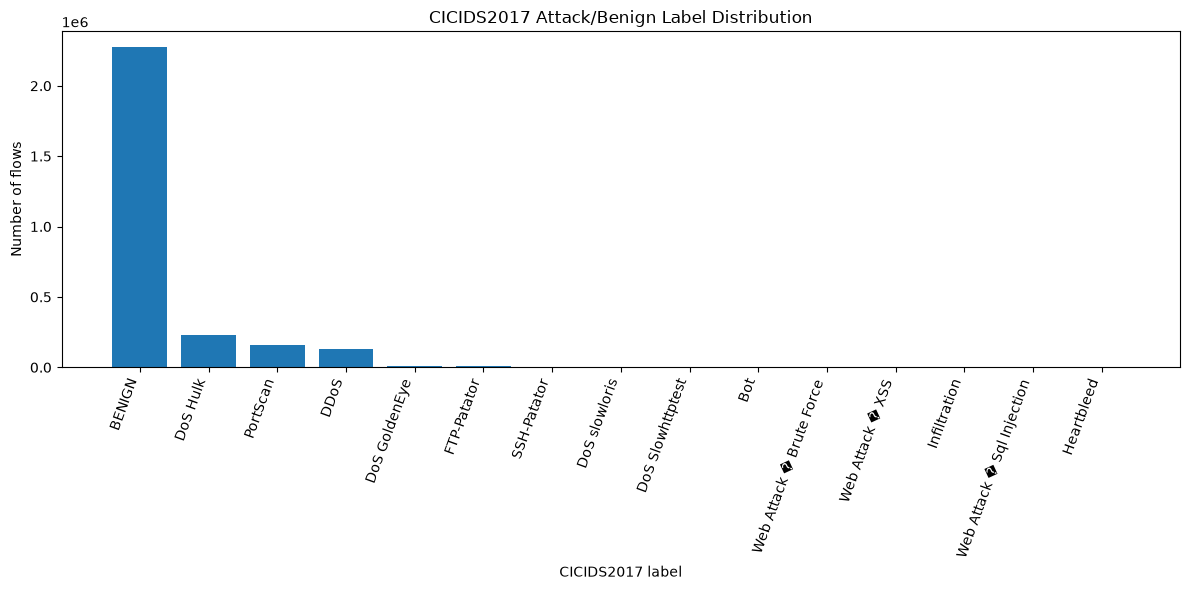

In [43]:
# ============================================================
# 16. Plot Label Distribution
# ============================================================

plt.figure(figsize=(12, 6))
plt.bar(label_counts["label"].astype(str), label_counts["count"])
plt.xticks(rotation=70, ha="right")
plt.ylabel("Number of flows")
plt.xlabel("CICIDS2017 label")
plt.title("CICIDS2017 Attack/Benign Label Distribution")
plt.tight_layout()
plt.show()


# 17. Source File / Day Analysis

CICIDS2017 is assembled from multiple capture periods. Examining each source file helps identify whether some attacks occur only in particular periods.

This matters directly for cross-dataset and distribution-shift analysis.


In [44]:
# ============================================================
# 17. Distribution by Source File
# ============================================================

file_label_counts = pd.crosstab(
    cicids["source_file"],
    cicids["label_eda"]
)

display(file_label_counts)

file_totals = file_label_counts.sum(axis=1).sort_values(ascending=False)
display(file_totals.to_frame("rows").reset_index().rename(columns={"index":"source_file"}))

file_label_counts.to_csv(OUTPUT_DIR / "source_file_label_counts.csv")


label_eda,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack � Brute Force,Web Attack � Sql Injection,Web Attack � XSS
source_file,,,,,,,,,,,,,,,
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,97718,0,128027,0,0,0,0,0,0,0,0,0,0,0,0
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,127537,0,0,0,0,0,0,0,0,0,158930,0,0,0,0
Friday-WorkingHours-Morning.pcap_ISCX.csv,189067,1966,0,0,0,0,0,0,0,0,0,0,0,0,0
Monday-WorkingHours.pcap_ISCX.csv,529918,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288566,0,0,0,0,0,0,0,0,36,0,0,0,0,0
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,168186,0,0,0,0,0,0,0,0,0,0,0,1507,21,652
Tuesday-WorkingHours.pcap_ISCX.csv,432074,0,0,0,0,0,0,7938,0,0,0,5897,0,0,0
Wednesday-workingHours.pcap_ISCX.csv,440031,0,0,10293,231073,5499,5796,0,11,0,0,0,0,0,0


,source_file,rows
0,Wednesday-workingHours.pcap_ISCX.csv,692703
1,Monday-WorkingHours.pcap_ISCX.csv,529918
2,Tuesday-WorkingHours.pcap_ISCX.csv,445909
3,Thursday-WorkingHours-Afternoon-Infilteration....,288602
4,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467
5,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745
6,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033
7,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366


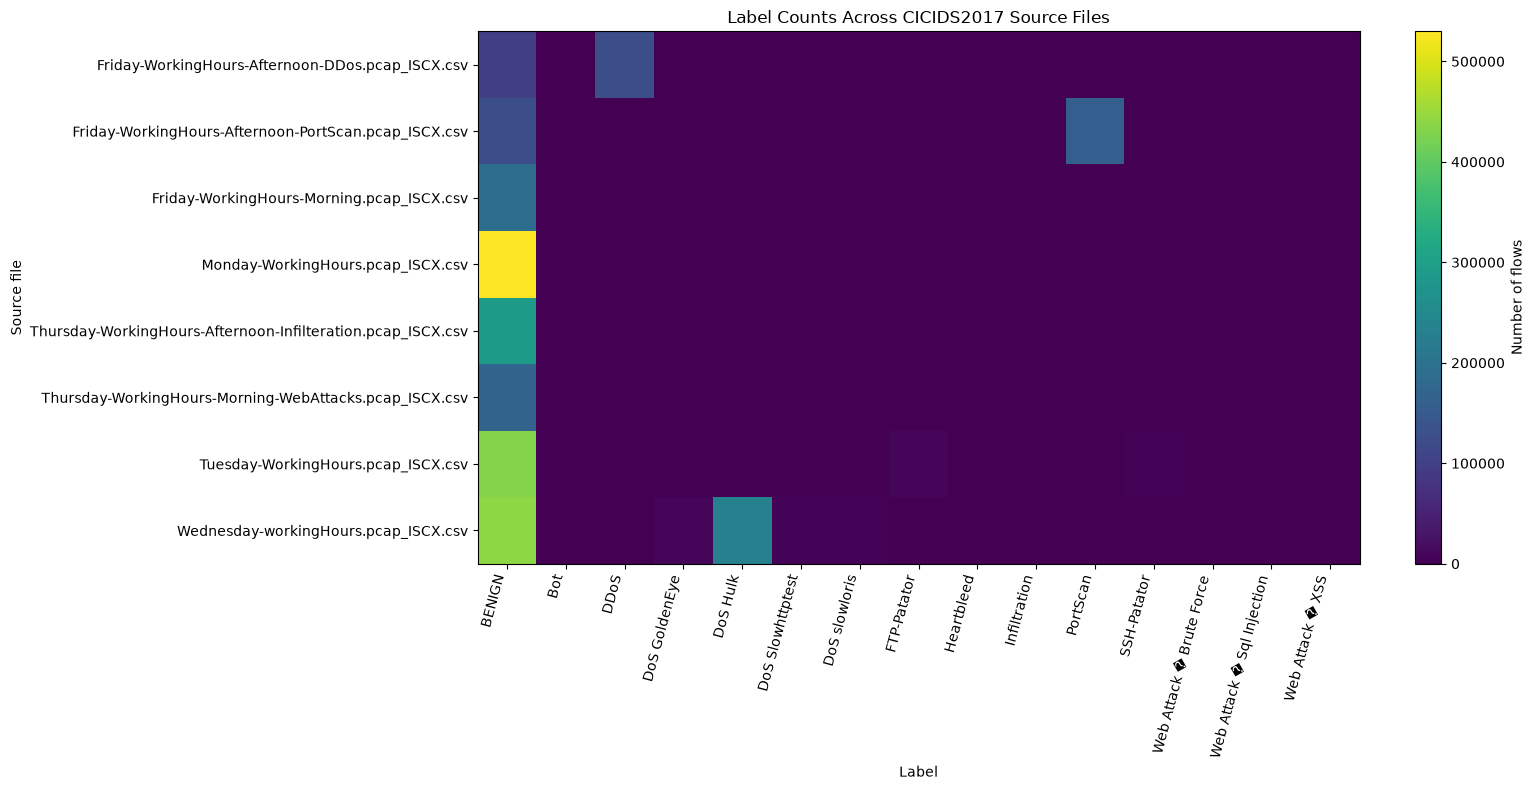

In [45]:
# ============================================================
# 18. Attack Types by Source File — Heatmap
# ============================================================

plt.figure(figsize=(16, 8))
plt.imshow(file_label_counts.values, aspect="auto")
plt.xticks(range(len(file_label_counts.columns)), file_label_counts.columns, rotation=75, ha="right")
plt.yticks(range(len(file_label_counts.index)), file_label_counts.index)
plt.xlabel("Label")
plt.ylabel("Source file")
plt.title("Label Counts Across CICIDS2017 Source Files")
plt.colorbar(label="Number of flows")
plt.tight_layout()
plt.show()


# 19. Numerical Feature Summary

We now examine the numerical features without transforming them.

Important questions:

- Which features have very large or very small scales?
- Which are highly skewed?
- Which contain many zeros?
- Which are constant or nearly constant?
- Which contain extreme values?


In [46]:
# ============================================================
# 19. Numeric Feature Summary
# ============================================================

# Exclude analysis-only columns
analysis_exclude = {"source_file", "label_eda", "binary_label_eda", "Label"}

model_numeric_cols = [
    c for c in cicids.select_dtypes(include=np.number).columns
    if c not in analysis_exclude
]

print("Numeric feature count:", len(model_numeric_cols))

numeric_summary = cicids[model_numeric_cols].describe().T
numeric_summary["missing"] = cicids[model_numeric_cols].isna().sum()
numeric_summary["zero_count"] = (cicids[model_numeric_cols] == 0).sum()
numeric_summary["zero_pct"] = 100 * numeric_summary["zero_count"] / len(cicids)

display(numeric_summary)
numeric_summary.to_csv(OUTPUT_DIR / "numeric_summary.csv")


Numeric feature count: 78


,count,mean,std,min,25%,50%,75%,max,missing,zero_count,zero_pct
Destination Port,"2,830,743.0000","8,071.4825","18,283.6322",0.0000,53.0000,80.0000,443.0000,"65,535.0000",0,1696,0.0599
Flow Duration,"2,830,743.0000","14,785,663.9295","33,653,744.0859",-13.0000,155.0000,"31,316.0000","3,204,828.5000","119,999,998.0000",0,2867,0.1013
Total Fwd Packets,"2,830,743.0000",9.3612,749.6728,1.0000,2.0000,2.0000,5.0000,"219,759.0000",0,0,0.0000
Total Backward Packets,"2,830,743.0000",10.3938,997.3883,0.0000,1.0000,2.0000,4.0000,"291,922.0000",0,453519,16.0212
Total Length of Fwd Packets,"2,830,743.0000",549.3024,"9,993.5892",0.0000,12.0000,62.0000,187.0000,"12,900,000.0000",0,449170,15.8676
Total Length of Bwd Packets,"2,830,743.0000","16,162.6425","2,263,088.0517",0.0000,0.0000,123.0000,482.0000,"655,453,030.0000",0,707746,25.0021
Fwd Packet Length Max,"2,830,743.0000",207.5999,717.1848,0.0000,6.0000,37.0000,81.0000,"24,820.0000",0,449170,15.8676
Fwd Packet Length Min,"2,830,743.0000",18.7137,60.3393,0.0000,0.0000,2.0000,36.0000,"2,325.0000",0,1317226,46.5329
Fwd Packet Length Mean,"2,830,743.0000",58.2019,186.0912,0.0000,6.0000,34.0000,50.0000,"5,940.8571",0,449170,15.8676
Fwd Packet Length Std,"2,830,743.0000",68.9101,281.1871,0.0000,0.0000,0.0000,26.1630,"7,125.5968",0,1850684,65.3780


In [47]:
# ============================================================
# 20. Skewness Analysis
# ============================================================

skewness_table = pd.DataFrame({
    "feature": model_numeric_cols,
    "skewness": [cicids[c].skew() for c in model_numeric_cols]
})

skewness_table["abs_skewness"] = skewness_table["skewness"].abs()
skewness_table = skewness_table.sort_values("abs_skewness", ascending=False)

display(skewness_table.head(30))

skewness_table.to_csv(OUTPUT_DIR / "feature_skewness.csv", index=False)


,feature,skewness,abs_skewness
55,Fwd Header Length.1,"-1,325.0738","1,325.0738"
34,Fwd Header Length,"-1,325.0738","1,325.0738"
4,Total Length of Fwd Packets,805.5705,805.5705
63,Subflow Fwd Bytes,803.5986,803.5986
35,Bwd Header Length,-717.0313,717.0313
69,min_seg_size_forward,-474.5353,474.5353
68,act_data_pkt_fwd,284.5952,284.5952
64,Subflow Bwd Packets,244.6795,244.6795
3,Total Backward Packets,244.6795,244.6795
62,Subflow Fwd Packets,244.3806,244.3806


### How to interpret skewness

A skewness value near 0 suggests a relatively symmetric distribution.

Large positive skewness means a long right tail, which is common for network-flow quantities such as packet counts, bytes, durations, or rates.

Strong skewness does **not** mean the feature should be deleted. It is an observation that may matter later when choosing preprocessing or models.


In [48]:
# ============================================================
# 21. Zero-Heavy Features
# ============================================================

zero_table = pd.DataFrame({
    "feature": model_numeric_cols,
    "zero_count": [(cicids[c] == 0).sum() for c in model_numeric_cols],
})

zero_table["zero_pct"] = 100 * zero_table["zero_count"] / len(cicids)
zero_table = zero_table.sort_values("zero_pct", ascending=False)

display(zero_table.head(30))
zero_table.to_csv(OUTPUT_DIR / "zero_value_analysis.csv", index=False)


,feature,zero_count,zero_pct
61,Bwd Avg Bulk Rate,2830743,100.0000
60,Bwd Avg Packets/Bulk,2830743,100.0000
56,Fwd Avg Bytes/Bulk,2830743,100.0000
57,Fwd Avg Packets/Bulk,2830743,100.0000
31,Bwd PSH Flags,2830743,100.0000
33,Bwd URG Flags,2830743,100.0000
58,Fwd Avg Bulk Rate,2830743,100.0000
59,Bwd Avg Bytes/Bulk,2830743,100.0000
49,CWE Flag Count,2830428,99.9889
32,Fwd URG Flags,2830428,99.9889


In [49]:
# ============================================================
# 22. Constant and Near-Constant Features
# ============================================================

cardinality_table = pd.DataFrame({
    "feature": model_numeric_cols,
    "unique_values": [cicids[c].nunique(dropna=False) for c in model_numeric_cols]
})

cardinality_table["unique_pct"] = 100 * cardinality_table["unique_values"] / len(cicids)

constant_features = cardinality_table[cardinality_table["unique_values"] <= 1].copy()
near_constant_features = cardinality_table[
    cardinality_table["unique_pct"] <= 0.01
].copy()

print("Constant features:")
display(constant_features)

print("\nFeatures with <= 0.01% unique values:")
display(near_constant_features)

cardinality_table.to_csv(OUTPUT_DIR / "feature_cardinality.csv", index=False)


Constant features:


,feature,unique_values,unique_pct
31,Bwd PSH Flags,1,0.0000
33,Bwd URG Flags,1,0.0000
56,Fwd Avg Bytes/Bulk,1,0.0000
57,Fwd Avg Packets/Bulk,1,0.0000
58,Fwd Avg Bulk Rate,1,0.0000
59,Bwd Avg Bytes/Bulk,1,0.0000
60,Bwd Avg Packets/Bulk,1,0.0000
61,Bwd Avg Bulk Rate,1,0.0000



Features with <= 0.01% unique values:


,feature,unique_values,unique_pct
30,Fwd PSH Flags,2,0.0001
31,Bwd PSH Flags,1,0.0000
32,Fwd URG Flags,2,0.0001
33,Bwd URG Flags,1,0.0000
38,Min Packet Length,215,0.0076
43,FIN Flag Count,2,0.0001
44,SYN Flag Count,2,0.0001
45,RST Flag Count,2,0.0001
46,PSH Flag Count,2,0.0001
47,ACK Flag Count,2,0.0001


# 23. Categorical / Non-Numeric Columns

Not every column is necessarily numeric. We inspect non-numeric columns because categorical/time-related fields can influence preprocessing and cross-dataset alignment later.


In [50]:
# ============================================================
# 23. Non-Numeric Columns
# ============================================================

non_numeric_cols = [
    c for c in cicids.columns
    if c not in model_numeric_cols
]

non_numeric_info = []

for c in non_numeric_cols:
    non_numeric_info.append({
        "column": c,
        "dtype": str(cicids[c].dtype),
        "unique_values": cicids[c].nunique(dropna=True),
        "missing": cicids[c].isna().sum()
    })

display(pd.DataFrame(non_numeric_info))


,column,dtype,unique_values,missing
0,Label,str,15,0
1,source_file,str,8,0
2,label_eda,string,15,0
3,binary_label_eda,str,2,0


# 24. Correlation Analysis

Correlation helps identify redundant numerical features.

A high correlation does **not** automatically mean a feature should be removed. It is evidence to consider during later feature analysis.

Because CICIDS2017 contains many features, we report the strongest absolute correlations and visualize the matrix.


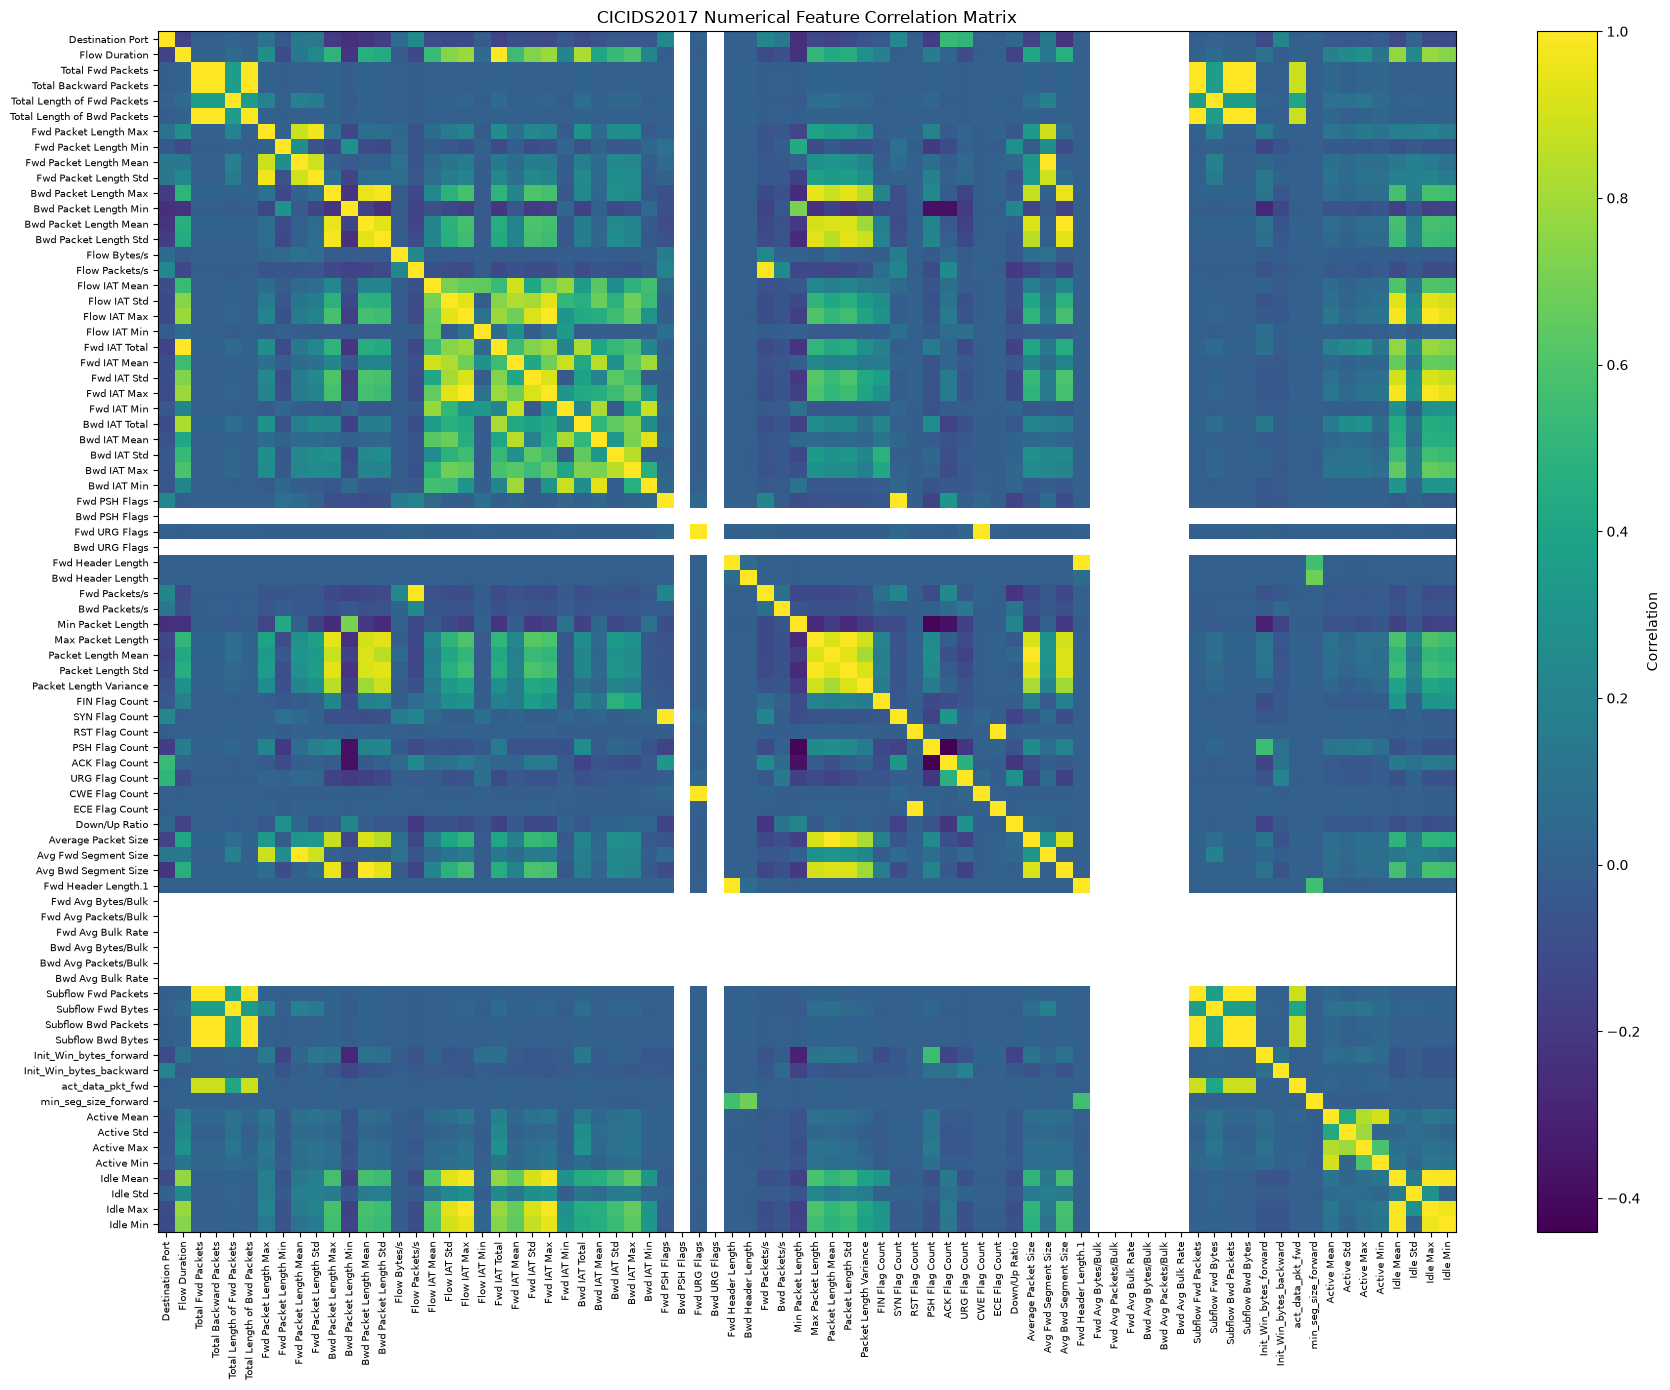

In [51]:
# ============================================================
# 24. Correlation Matrix
# ============================================================

corr = cicids[model_numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(18, 14))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr.index)), corr.index, fontsize=7)
plt.title("CICIDS2017 Numerical Feature Correlation Matrix")
plt.colorbar(label="Correlation")
plt.tight_layout()
plt.show()


In [52]:
# ============================================================
# 25. Highly Correlated Feature Pairs
# ============================================================

corr_pairs = []

cols = corr.columns

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        value = corr.iloc[i, j]
        if pd.notna(value):
            corr_pairs.append({
                "feature_1": cols[i],
                "feature_2": cols[j],
                "correlation": value,
                "absolute_correlation": abs(value)
            })

high_corr = (
    pd.DataFrame(corr_pairs)
    .sort_values("absolute_correlation", ascending=False)
)

display(high_corr.head(40))
high_corr.to_csv(OUTPUT_DIR / "high_correlation_pairs.csv", index=False)


,feature_1,feature_2,correlation,absolute_correlation
256,Total Backward Packets,Subflow Bwd Packets,1.0000,1.0000
1646,Fwd PSH Flags,SYN Flag Count,1.0000,1.0000
566,Fwd Packet Length Mean,Avg Fwd Segment Size,1.0000,1.0000
1689,Fwd URG Flags,CWE Flag Count,1.0000,1.0000
1732,Fwd Header Length,Fwd Header Length.1,1.0000,1.0000
188,Total Fwd Packets,Subflow Fwd Packets,1.0000,1.0000
801,Bwd Packet Length Mean,Avg Bwd Segment Size,1.0000,1.0000
386,Total Length of Bwd Packets,Subflow Bwd Bytes,1.0000,1.0000
320,Total Length of Fwd Packets,Subflow Fwd Bytes,1.0000,1.0000
190,Total Fwd Packets,Subflow Bwd Packets,0.9991,0.9991


OSError: Cannot save file into a non-existent directory: 'C:\Users\BISMILLAH\Documents\NetShield\outputs\CICIDS2017_EDA'

# 26. Feature Distributions

Plotting every feature individually can produce a huge notebook. Instead, we automatically select a manageable group of numerical features based on skewness and visualize their distributions.

For very large datasets, a sample is used **only for plotting**. Statistical counts and summaries above use the full dataset.


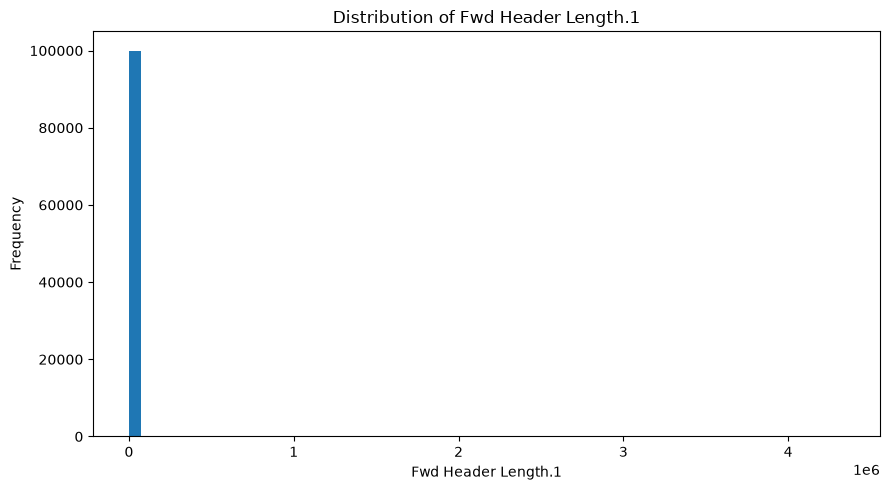

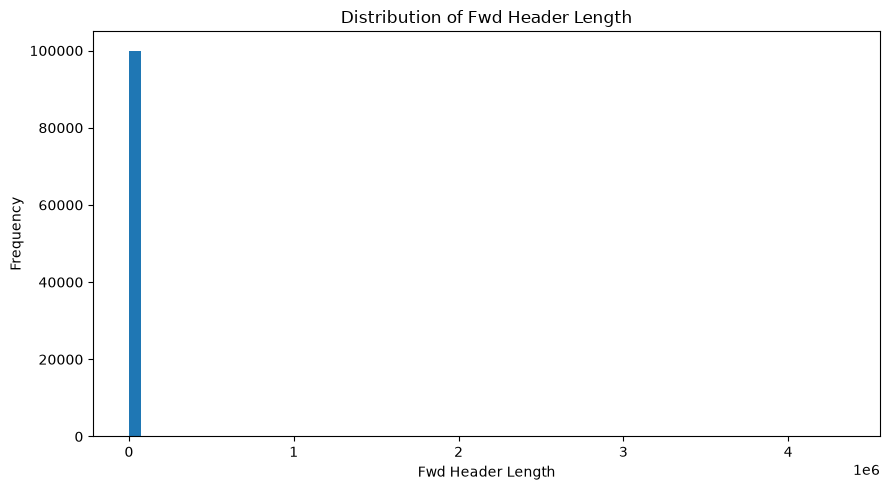

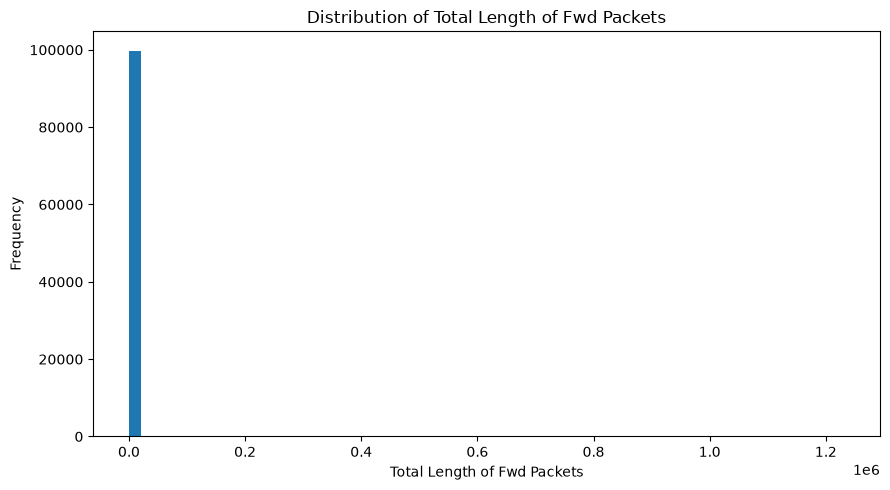

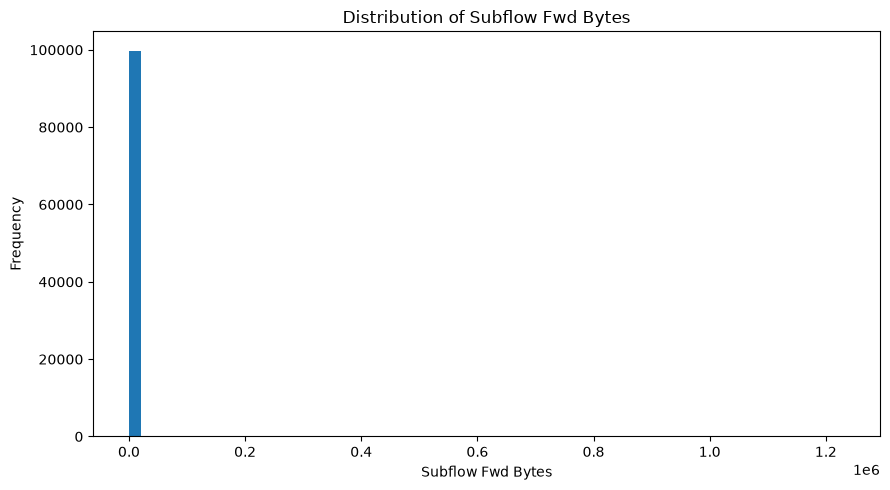

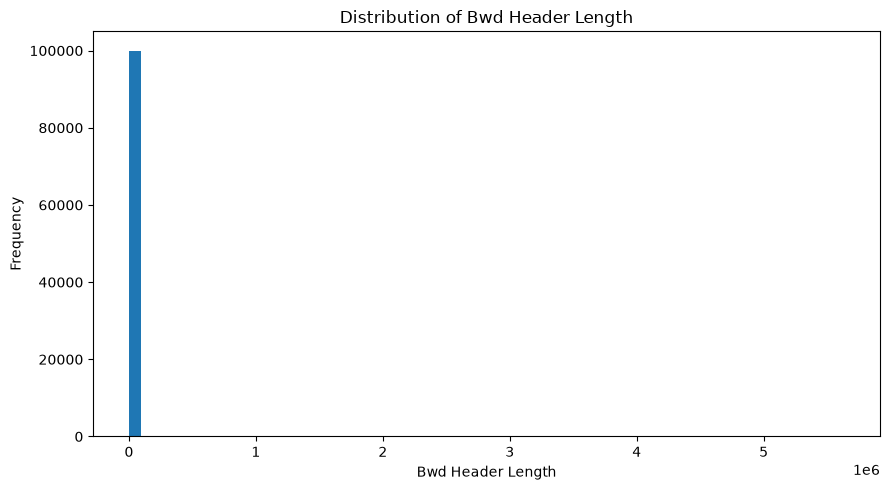

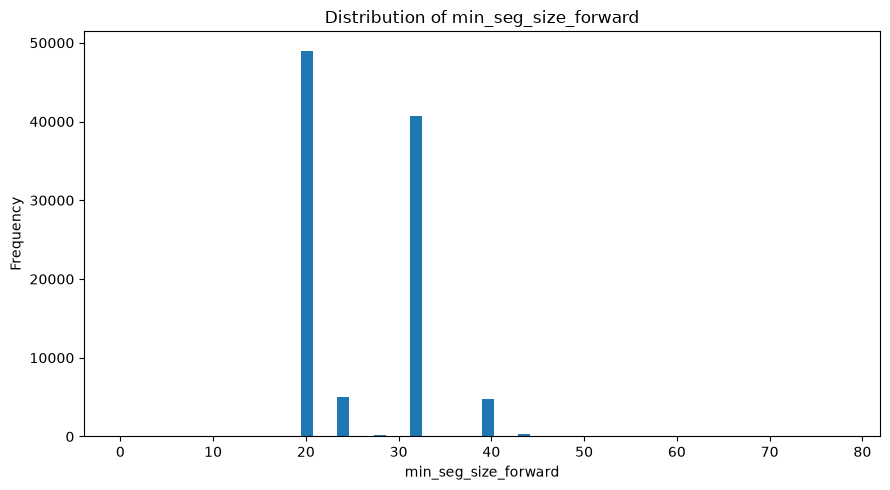

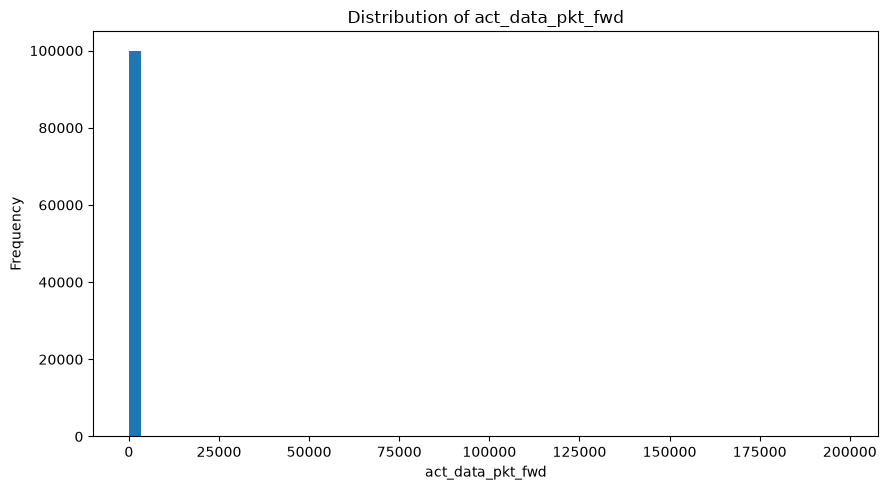

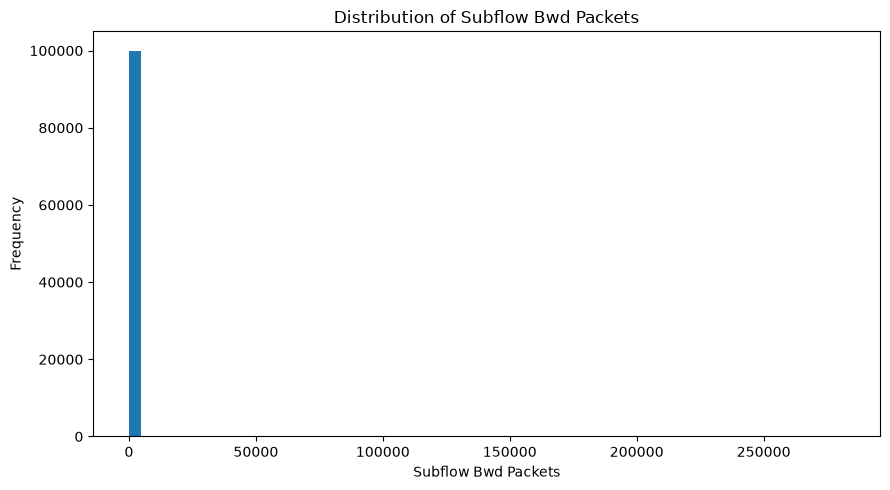

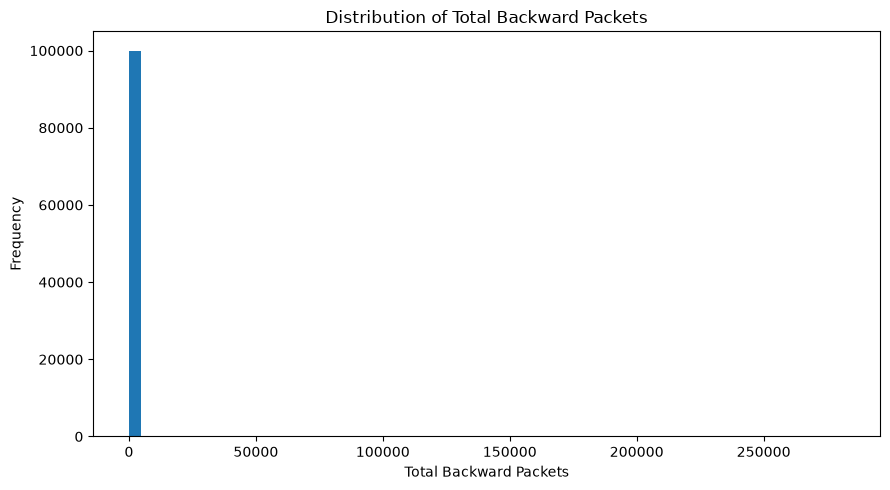

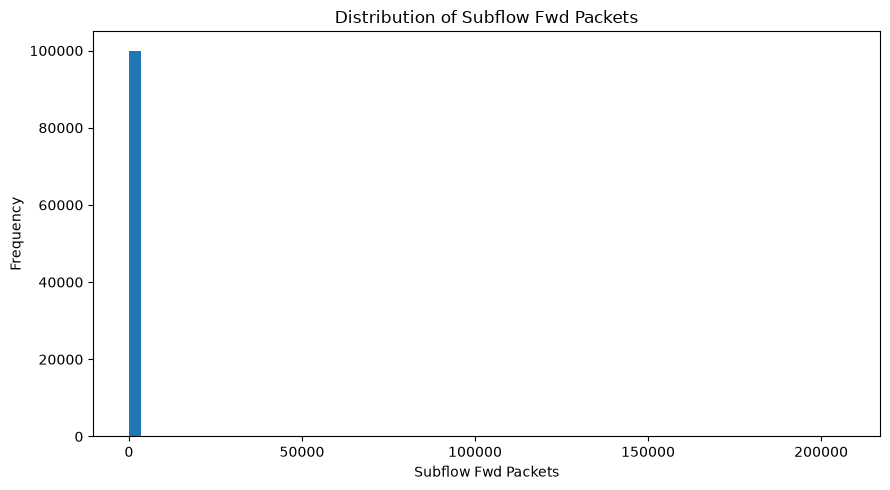

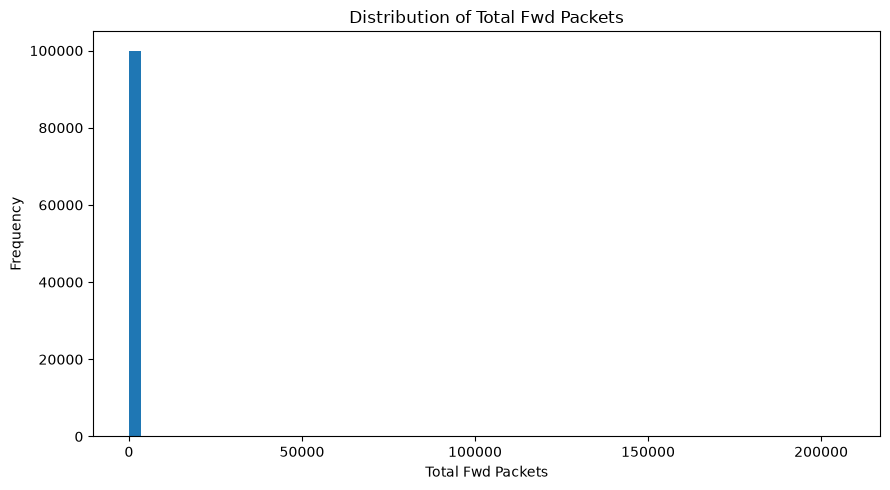

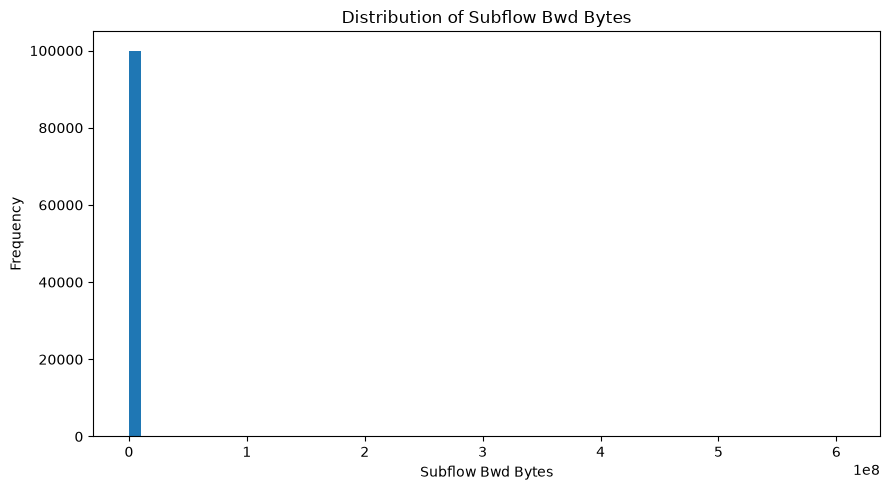

In [ ]:
# ============================================================
# 26. Distribution Plots
# ============================================================

PLOT_SAMPLE_SIZE = min(100_000, len(cicids))
plot_sample = cicids.sample(PLOT_SAMPLE_SIZE, random_state=42) if len(cicids) > PLOT_SAMPLE_SIZE else cicids.copy()

top_distribution_features = (
    skewness_table.head(12)["feature"].tolist()
)

for col in top_distribution_features:
    values = pd.to_numeric(plot_sample[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    if values.empty:
        continue

    plt.figure(figsize=(9, 5))
    plt.hist(values, bins=60)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()


# 27. Boxplots for Extreme-Value Inspection

Boxplots provide a quick visual indication of extreme observations.

Because network-flow features can have very large ranges, the plots below use a sampled subset and focus on selected features.


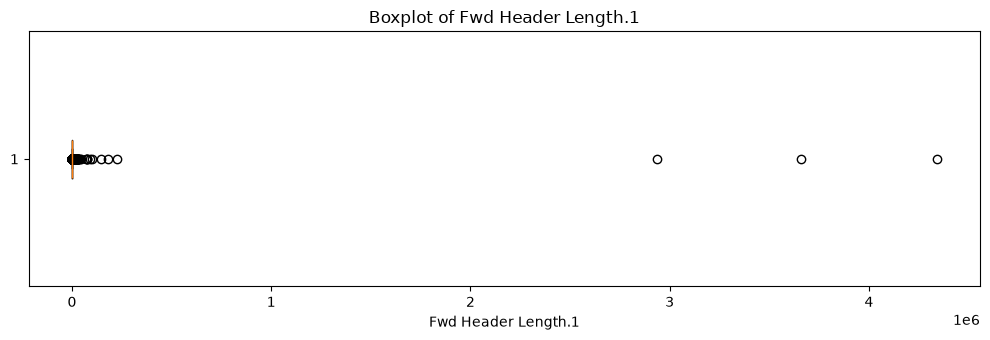

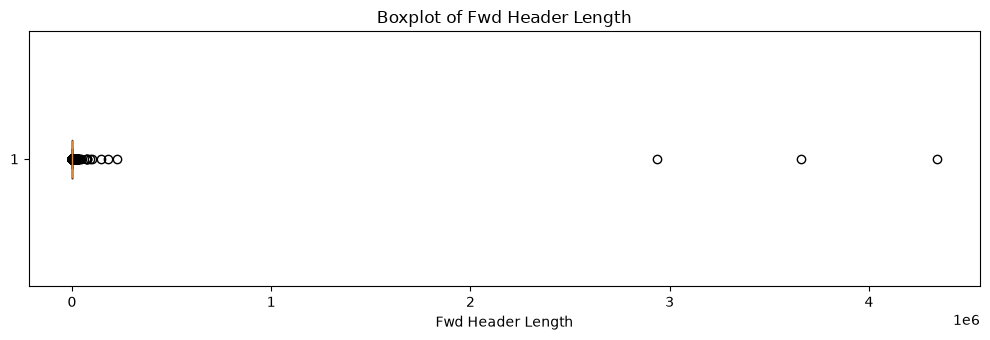

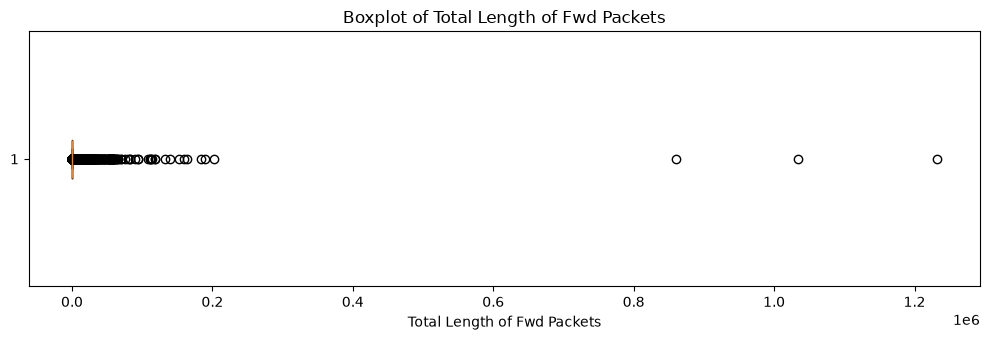

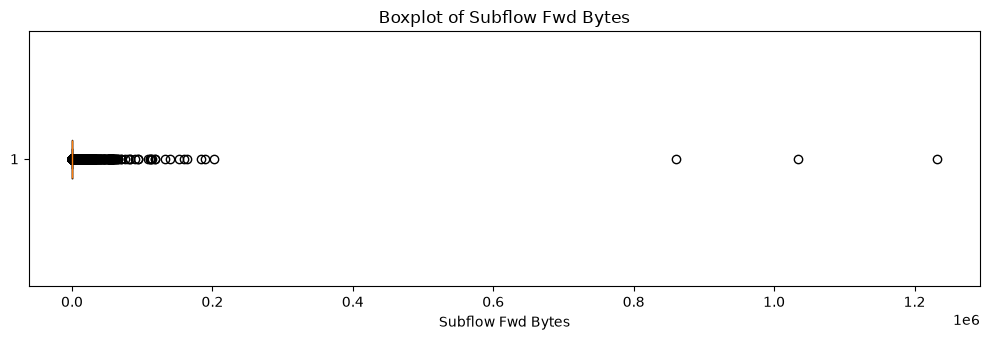

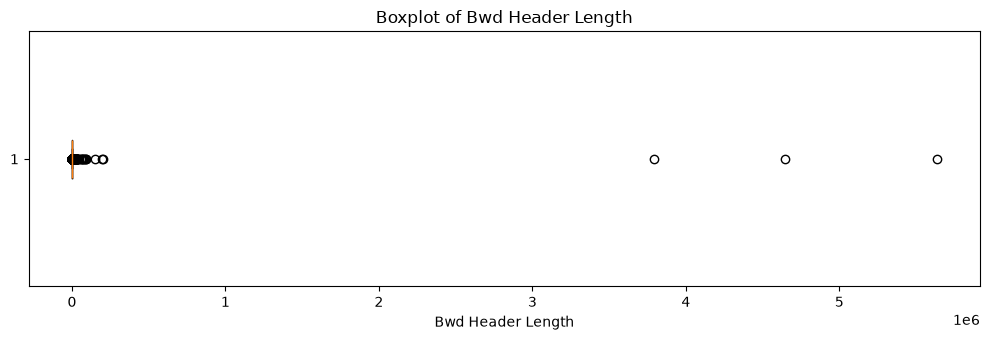

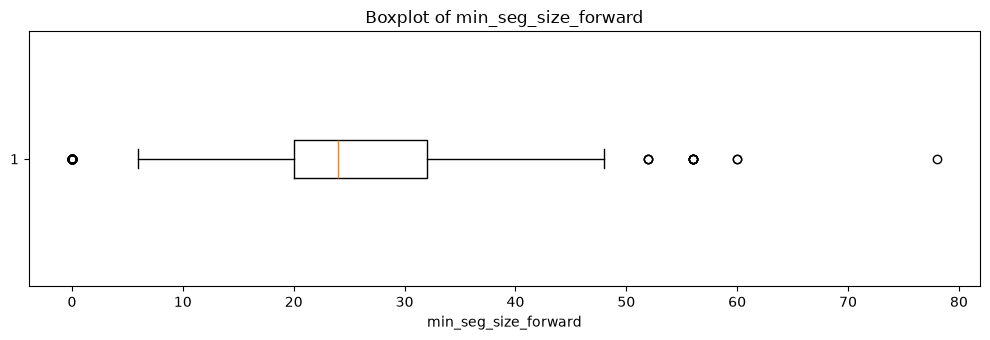

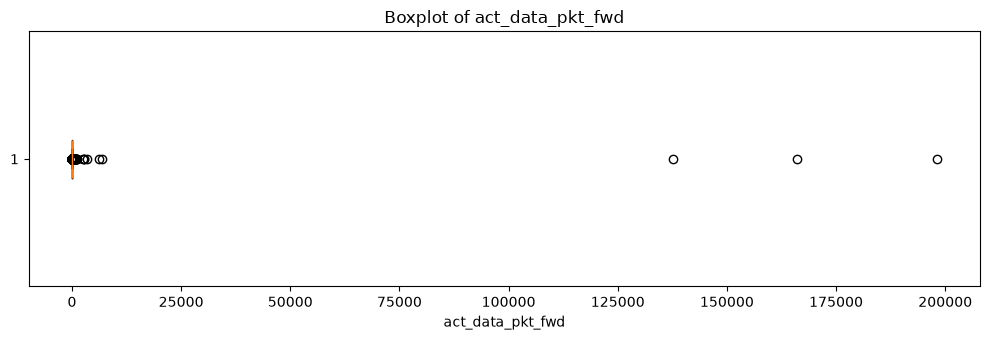

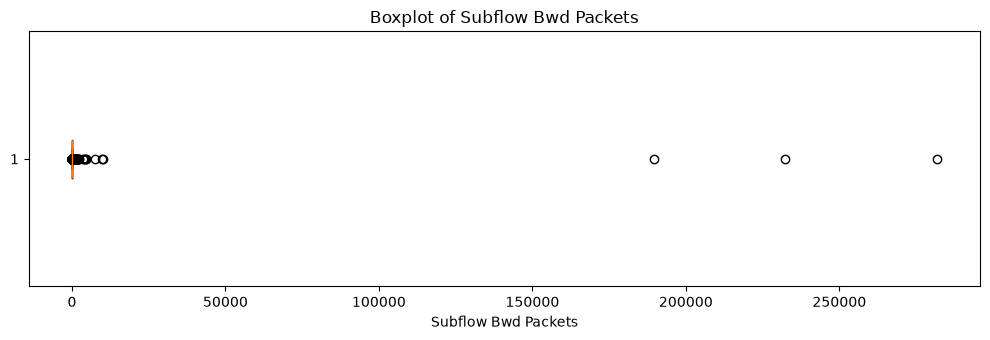

In [ ]:
# ============================================================
# 27. Boxplots
# ============================================================

boxplot_features = top_distribution_features[:8]

for col in boxplot_features:
    values = pd.to_numeric(plot_sample[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    if values.empty:
        continue

    plt.figure(figsize=(10, 3.5))
    plt.boxplot(values, vert=False)
    plt.xlabel(col)
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()


# 28. Feature Behavior by Attack Label

This section is particularly important for NetShield.

A feature can have a very different distribution for different attack categories. Such differences may help a model distinguish classes within CICIDS2017 but may not transfer to another dataset if the other dataset measures or represents traffic differently.

We therefore compare selected features across the most common labels.


In [ ]:
# ============================================================
# 28. Select Common Labels
# ============================================================

TOP_LABELS_FOR_PLOTS = 8

top_labels = (
    cicids["label_eda"]
    .value_counts()
    .head(TOP_LABELS_FOR_PLOTS)
    .index
    .tolist()
)

print("Labels selected for detailed feature comparisons:")
for label in top_labels:
    print("-", label)


Labels selected for detailed feature comparisons:
- BENIGN
- DoS Hulk
- PortScan
- DDoS
- DoS GoldenEye
- FTP-Patator
- SSH-Patator
- DoS slowloris


In [ ]:
# ============================================================
# 29. Feature Distributions by Label
# ============================================================

selected_feature_count = min(8, len(top_distribution_features))
selected_features = top_distribution_features[:selected_feature_count]

for feature in selected_features:
    temp = cicids[cicids["label_eda"].isin(top_labels)][["label_eda", feature]].copy()
    temp[feature] = pd.to_numeric(temp[feature], errors="coerce")
    temp[feature] = temp[feature].replace([np.inf, -np.inf], np.nan)
    temp = temp.dropna()

    if temp.empty:
        continue

    groups = [
        temp.loc[temp["label_eda"] == label, feature].values
        for label in top_labels
    ]

    plt.figure(figsize=(14, 6))
    plt.boxplot(groups, labels=top_labels, showfliers=False)
    plt.xticks(rotation=65, ha="right")
    plt.ylabel(feature)
    plt.title(f"{feature} by Top CICIDS2017 Labels")
    plt.tight_layout()
    plt.show()


TypeError: boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

<Figure size 1400x600 with 0 Axes>

# 30. Class-Wise Numerical Statistics

For the most common attack labels, calculate median and quartile information for selected numerical features.

Median is especially useful for network data because extreme values can make means difficult to interpret.


In [ ]:
# ============================================================
# 30. Class-Wise Statistics
# ============================================================

classwise_tables = []

for label in top_labels:
    subset = cicids[cicids["label_eda"] == label]

    for feature in selected_features:
        values = pd.to_numeric(subset[feature], errors="coerce")
        values = values.replace([np.inf, -np.inf], np.nan).dropna()

        if len(values) == 0:
            continue

        classwise_tables.append({
            "label": label,
            "feature": feature,
            "count": len(values),
            "mean": values.mean(),
            "median": values.median(),
            "std": values.std(),
            "q1": values.quantile(0.25),
            "q3": values.quantile(0.75)
        })

classwise_stats = pd.DataFrame(classwise_tables)
display(classwise_stats.head(50))

classwise_stats.to_csv(OUTPUT_DIR / "classwise_feature_statistics.csv", index=False)


# 31. Relationship Between Features and the Binary Target

A simple diagnostic is to compare numerical feature distributions between Benign and Attack flows.

This is **not** feature selection. It is only exploratory evidence about how the target relates to the observed features.


In [ ]:
# ============================================================
# 31. Benign vs Attack Feature Comparison
# ============================================================

binary_plot_features = selected_features[:6]

for feature in binary_plot_features:
    temp = cicids[["binary_label_eda", feature]].copy()
    temp[feature] = pd.to_numeric(temp[feature], errors="coerce")
    temp[feature] = temp[feature].replace([np.inf, -np.inf], np.nan)
    temp = temp.dropna()

    groups = []
    labels = []

    for group in ["Benign", "Attack"]:
        vals = temp.loc[temp["binary_label_eda"] == group, feature].values
        if len(vals):
            groups.append(vals)
            labels.append(group)

    if not groups:
        continue

    plt.figure(figsize=(8, 5))
    plt.boxplot(groups, labels=labels, showfliers=False)
    plt.ylabel(feature)
    plt.title(f"{feature}: Benign vs Attack")
    plt.tight_layout()
    plt.show()


# 32. Statistical Train/Test Leakage Check — Preparation for Later

This notebook does not define the final train/test split because the NetShield methodology requires preprocessing and feature selection to be performed using training data only.

However, the EDA records the dataset's structural properties so that the later preprocessing notebook can create a reproducible split without contaminating transformations with test information.

**Do not use these EDA statistics to fit scalers, encoders, imputers, feature selectors, or resampling methods.**


# 33. Suspicious / Diagnostic Values

We look for values that deserve attention before modeling:

- negative values in features where negative values may be unusual,
- extremely large magnitudes,
- columns with almost no variation,
- non-numeric values inside otherwise numerical-looking columns.

This is a diagnostic stage; it does not automatically decide that a value is invalid.


In [ ]:
# ============================================================
# 33. Numeric Range Diagnostics
# ============================================================

range_diagnostics = []

for col in model_numeric_cols:
    s = pd.to_numeric(cicids[col], errors="coerce")
    finite = s.replace([np.inf, -np.inf], np.nan).dropna()

    if finite.empty:
        continue

    range_diagnostics.append({
        "feature": col,
        "min": finite.min(),
        "max": finite.max(),
        "negative_count": int((finite < 0).sum()),
        "negative_pct": 100 * (finite < 0).mean(),
        "finite_count": len(finite)
    })

range_diagnostics = pd.DataFrame(range_diagnostics)

display(
    range_diagnostics.sort_values("negative_count", ascending=False).head(30)
)

range_diagnostics.to_csv(OUTPUT_DIR / "range_diagnostics.csv", index=False)


# 34. Compact Dataset Profile

This table provides a single place to review the main structural properties discovered during EDA.


In [ ]:
# ============================================================
# 34. Dataset Profile
# ============================================================

profile = {
    "total_rows": len(cicids),
    "total_columns_in_memory": cicids.shape[1],
    "original_csv_files": len(csv_files),
    "numeric_features": len(model_numeric_cols),
    "non_numeric_columns": len(non_numeric_cols),
    "unique_labels": cicids["label_eda"].nunique(dropna=True),
    "exact_duplicate_rows": int(cicids.duplicated().sum()),
    "columns_with_missing_values": int((cicids.isna().sum() > 0).sum()),
    "constant_numeric_features": int(len(constant_features)),
    "near_constant_numeric_features": int(len(near_constant_features)),
    "features_with_infinite_values": int(len(inf_table)) if not inf_table.empty else 0
}

profile_df = pd.DataFrame(list(profile.items()), columns=["metric", "value"])
display(profile_df)

profile_df.to_csv(OUTPUT_DIR / "dataset_profile.csv", index=False)


# 35. Main EDA Findings — Automatically Generated

The following cell summarizes the most important findings using the actual data loaded above.

This is intentionally generated from the dataset rather than hard-coding expected CICIDS2017 values.


In [ ]:
# ============================================================
# 35. Automatic Findings
# ============================================================

print("=" * 80)
print("CICIDS2017 EDA — AUTOMATIC SUMMARY")
print("=" * 80)

print(f"1. Dataset size: {len(cicids):,} rows across {len(csv_files)} source CSV files.")
print(f"2. Number of unique labels: {cicids['label_eda'].nunique(dropna=True)}.")

print("\n3. Most common labels:")
display(label_counts.head(10))

print("\n4. Class distribution:")
display(binary_counts)

print(f"5. Exact duplicate rows: {duplicate_count:,} ({duplicate_pct:.4f}%).")

missing_total = int(cicids.isna().sum().sum())
print(f"6. Total NaN cells: {missing_total:,}.")

if inf_table.empty:
    print("7. Infinite numeric values: none detected.")
else:
    print(f"7. Features containing infinite values: {len(inf_table)}.")
    display(inf_table.head(10))

print("\n8. Most skewed numerical features:")
display(skewness_table.head(10)[["feature", "skewness"]])

print("\n9. Most zero-heavy numerical features:")
display(zero_table.head(10)[["feature", "zero_pct"]])

print("\n10. Strongest feature correlations:")
display(high_corr.head(10)[["feature_1", "feature_2", "correlation"]])

print("\n11. Constant features:")
if constant_features.empty:
    print("None.")
else:
    display(constant_features)

print("=" * 80)


# 36. What This Means for NetShield

The EDA should now give us evidence for several parts of the NetShield research question.

### A. Class imbalance
The label and binary-class distributions show whether CICIDS2017 is strongly imbalanced. This justifies using metrics such as **Macro-F1, Recall, Precision, PR-AUC, and FPR** rather than relying on accuracy alone.

### B. Dataset distribution
The source-file analysis shows whether different attack types are concentrated in particular capture periods. Such concentration can contribute to distribution shift.

### C. Feature behavior
Skewness, zero-heavy features, extreme values, and class-wise feature distributions reveal the statistical structure that later models will learn.

### D. Redundancy
Highly correlated features may represent overlapping information. This should be considered during later feature analysis, but features should not be removed merely because they are correlated.

### E. Cross-dataset relevance
The most important point for NetShield is that **CICIDS2017 cannot be analyzed in isolation**. Its feature names, distributions, traffic characteristics, and attack-label structure will later be compared with UNSW-NB15.

### F. Preprocessing comes next
Only after both datasets have been explored should we build the training pipelines. Transformations and feature selection must be fitted on training data only to avoid leakage.


# 37. Save the Cleaned EDA Metadata

We save diagnostic tables and a compact metadata file.

**The raw CICIDS2017 CSV files are never overwritten.**


In [ ]:
# ============================================================
# 37. Save Final Metadata
# ============================================================

metadata = {
    "project": "NetShield",
    "dataset": "CICIDS2017",
    "rows": int(len(cicids)),
    "columns_in_memory": int(cicids.shape[1]),
    "source_files": int(len(csv_files)),
    "numeric_features": int(len(model_numeric_cols)),
    "unique_labels": int(cicids["label_eda"].nunique(dropna=True)),
    "exact_duplicates": int(cicids.duplicated().sum()),
    "nan_cells": int(cicids.isna().sum().sum()),
    "eda_only_note": "No scaling, encoding, imputation, SMOTE, feature selection, or raw-data deletion performed."
}

pd.Series(metadata).to_json(
    OUTPUT_DIR / "cicids_eda_metadata.json",
    indent=4
)

print("EDA outputs saved to:")
print(OUTPUT_DIR)


# 38. Final Checklist

Before moving to preprocessing, confirm that you have inspected:

- [x] Dataset/file structure
- [x] Number of rows and columns
- [x] Data types
- [x] Missing values
- [x] Infinite values
- [x] Duplicate flows
- [x] Label distribution
- [x] Benign vs attack imbalance
- [x] Attack distribution by source file
- [x] Numerical descriptive statistics
- [x] Skewness
- [x] Zero-heavy features
- [x] Constant / near-constant features
- [x] Cardinality
- [x] Extreme values
- [x] Feature correlations
- [x] Feature distributions
- [x] Feature behavior by attack label
- [x] Benign vs attack feature behavior
- [x] Diagnostic range checks
- [x] NetShield interpretation

## Next notebook

After reviewing this EDA, the next stage should be the **CICIDS2017 preprocessing pipeline**, alongside a corresponding UNSW-NB15 preprocessing pipeline.

Those pipelines should handle the actual train/test split and training-only preprocessing required for the NetShield experiments.
